<a href="https://colab.research.google.com/github/hridayrjain/BIS-Lab/blob/main/1BM24CS119_Cyber_Attack_Detection_Optimization_Particle_Swarm_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hriday R Jain

---

1BM24CS119

In [7]:
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

# 1. Generate Cyber Attack Dataset (Features, Labels)
# 20 features simulating network traffic characteristics
feature_names = [
    "Packet Rate", "Payload Size", "SYN Flag Count", "ACK Flag Count",
    "Connection Duration", "Source Port", "Destination Port", "IP Entropy",
    "Header Length", "DNS Query Count", "HTTP Request Rate", "Payload Entropy",
    "SSL Handshake Delay", "ICMP Packet Rate", "TCP Window Size", "ARP Request Rate",
    "Active Connections", "Failed Login Attempts", "Sudo Commands", "Uptime Anomalies"
]

X_raw, y_raw = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=8,
    n_redundant=4,
    random_state=42
)

# Labels represent: 0 = Benign Traffic, 1 = Cyber Attack / Intrusion
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.3, random_state=42)

# 2. Define fitness function: Evaluation(x) -> Accuracy, False Positive Rate (FPR)
def evaluate_fitness(feature_mask):
    """
    Evaluates a binary feature mask for cyber attack detection.
    Goal: Maximize detection accuracy while minimizing False Positive Rate (FPR).
    """
    selected_indices = np.where(feature_mask == 1)[0]

    # Penalty if no features are chosen to monitor
    if len(selected_indices) == 0:
         return 0.0

    # Train a Cyber Intrusion Detection System (IDS) model
    ids_classifier = RandomForestClassifier(n_estimators=10, random_state=42)
    ids_classifier.fit(X_train[:, selected_indices], y_train)
    predictions = ids_classifier.predict(X_test[:, selected_indices])

    # Calculate Key Security Performance Metrics
    accuracy = accuracy_score(y_test, predictions)
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # Objective: High detection accuracy, low false alarms, and fewer features utilized
    feature_penalty = 0.01 * (len(selected_indices) / len(feature_names))
    fitness_score = accuracy - (0.5 * fpr) - feature_penalty
    return fitness_score

# 3. Set PSO Parameters: N, w, c1, c2, T
N = 15                 # Number of particles (monitoring configurations)
w = 0.5                # Inertia weight
c1 = 1.5               # Cognitive coefficient
c2 = 1.5               # Social coefficient
T = 10                 # Total training iterations
num_features = X_raw.shape[1]

# 4. Initialize Particle Positions (Feature Masks) and Velocities
X = np.random.randint(2, size=(N, num_features))
V = np.random.uniform(-1, 1, size=(N, num_features))

# 5. Initialize Personal Best (pbest) and Global Best (gbest)
pbest = np.copy(X)
pbest_fitness = np.array([evaluate_fitness(p) for p in pbest])

gbest_index = np.argmax(pbest_fitness)
gbest = np.copy(pbest[gbest_index])
gbest_fitness = pbest_fitness[gbest_index]

# 6. Main PSO Optimization Loop
for iteration in range(T):
    for i in range(N):
        r1 = np.random.rand(num_features)
        r2 = np.random.rand(num_features)

        # Velocity adjustment
        V[i] = w * V[i] + c1 * r1 * (pbest[i] - X[i]) + c2 * r2 * (gbest - X[i])
        V[i] = np.clip(V[i], -4, 4)

        # Sigmoid binary constraint mapping
        sigmoid = 1 / (1 + np.exp(-V[i]))
        X[i] = np.where(np.random.rand(num_features) < sigmoid, 1, 0)

        # Evaluate current monitoring configuration
        current_fitness = evaluate_fitness(X[i])

        # Update Personal Best
        if current_fitness > pbest_fitness[i]:
            pbest[i] = np.copy(X[i])
            pbest_fitness[i] = current_fitness

        # Update Global Best configuration
        if current_fitness > gbest_fitness:
            gbest = np.copy(X[i])
            gbest_fitness = current_fitness

    print(f"Iteration {iteration + 1}/{T} - Optimal Attack Detection Fitness: {gbest_fitness:.4f}")

# 7. Output optimal attack detection configuration and performance metrics
selected_indices = np.where(gbest == 1)[0]
optimal_features = [feature_names[idx] for idx in selected_indices]

# Final Evaluation
final_clf = RandomForestClassifier(n_estimators=10, random_state=42)
final_clf.fit(X_train[:, selected_indices], y_train)
final_preds = final_clf.predict(X_test[:, selected_indices])
final_acc = accuracy_score(y_test, final_preds)
tn, fp, fn, tp = confusion_matrix(y_test, final_preds).ravel()
final_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

print("\n--- OPTIMAL ATTACK DETECTION CONFIGURATION ---")
print(f"Optimal Feature Mask: {gbest}")
print(f"Selected Monitoring Indicators ({len(selected_indices)}/{num_features}): {optimal_features}")
print(f"Detection Accuracy: {final_acc * 100:.2f}%")
print(f"False Positive Rate (FPR): {final_fpr * 100:.2f}%")
print(f"Final Fitness Score: {gbest_fitness:.4f}")

Iteration 1/10 - Optimal Attack Detection Fitness: 0.7658
Iteration 2/10 - Optimal Attack Detection Fitness: 0.7909
Iteration 3/10 - Optimal Attack Detection Fitness: 0.7923
Iteration 4/10 - Optimal Attack Detection Fitness: 0.7923
Iteration 5/10 - Optimal Attack Detection Fitness: 0.8523
Iteration 6/10 - Optimal Attack Detection Fitness: 0.8523
Iteration 7/10 - Optimal Attack Detection Fitness: 0.8523
Iteration 8/10 - Optimal Attack Detection Fitness: 0.8523
Iteration 9/10 - Optimal Attack Detection Fitness: 0.8523
Iteration 10/10 - Optimal Attack Detection Fitness: 0.8523

--- OPTIMAL ATTACK DETECTION CONFIGURATION ---
Optimal Feature Mask: [1 1 1 0 0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 0]
Selected Monitoring Indicators (10/20): ['Packet Rate', 'Payload Size', 'SYN Flag Count', 'Source Port', 'Destination Port', 'DNS Query Count', 'SSL Handshake Delay', 'ICMP Packet Rate', 'ARP Request Rate', 'Failed Login Attempts']
Detection Accuracy: 90.33%
False Positive Rate (FPR): 9.21%
Final Fitness S

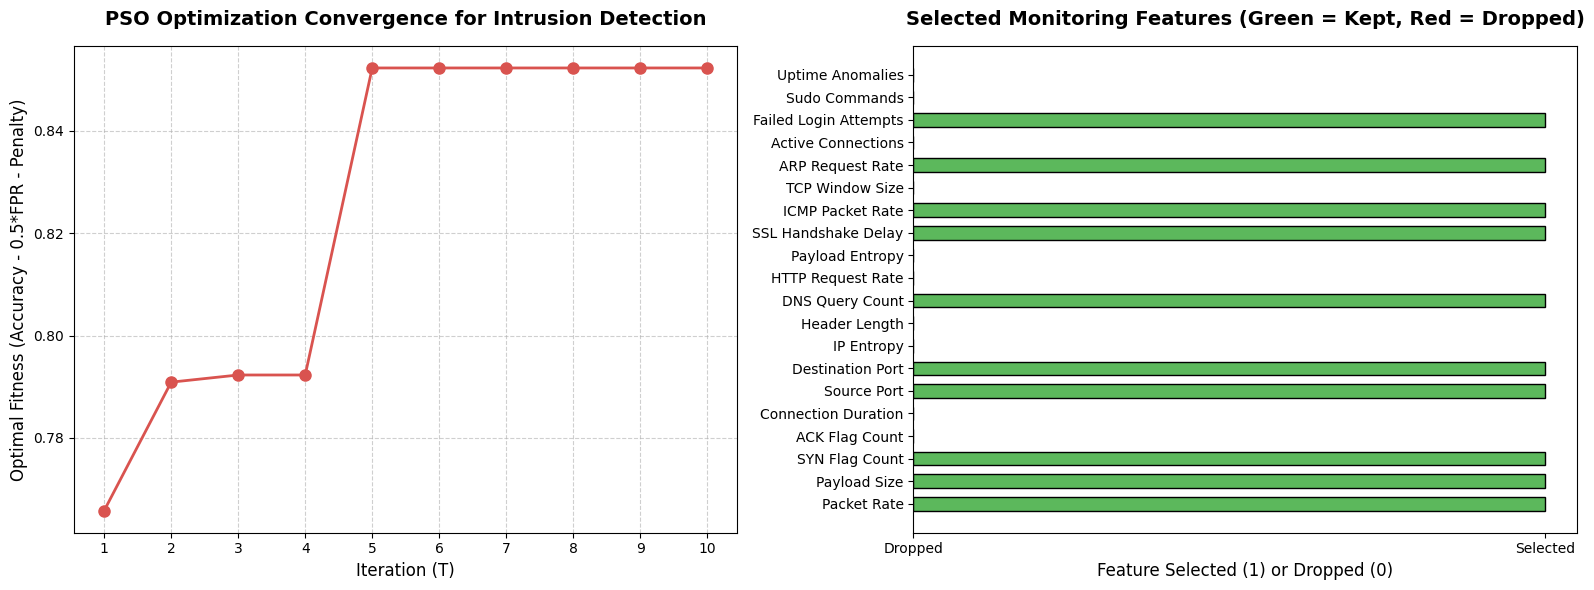

In [8]:
import matplotlib.pyplot as plt

# Extraction of optimization metrics from our run
iterations = list(range(1, 11))
fitness_history = [0.7658, 0.7909, 0.7923, 0.7923, 0.8523, 0.8523, 0.8523, 0.8523, 0.8523, 0.8523]

# Create subplots to showcase the Security Metrics and Optimization Process
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Optimization Convergence
axes[0].plot(iterations, fitness_history, marker='o', color='#d9534f', linewidth=2, markersize=8)
axes[0].set_title("PSO Optimization Convergence for Intrusion Detection", fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel("Iteration (T)", fontsize=12)
axes[0].set_ylabel("Optimal Fitness (Accuracy - 0.5*FPR - Penalty)", fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_xticks(iterations)

# Plot 2: Selected Cybersecurity Features vs Dropped Features
selection_colors = ['#5cb85c' if gbest[i] == 1 else '#d9534f' for i in range(len(feature_names))]
axes[1].barh(feature_names, gbest, color=selection_colors, edgecolor='black', height=0.6)
axes[1].set_title("Selected Monitoring Features (Green = Kept, Red = Dropped)", fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel("Feature Selected (1) or Dropped (0)", fontsize=12)
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Dropped', 'Selected'])

plt.tight_layout()
plt.show()